# Antibiotic Activity Oracle & Landscape Sparsity Diagnostic

- In EVA, every candidate molecule is scored by an activity predictor estimating the probability being active against a bacterial strain.
- The activity oracle is a **TabPFN classifier** trained on **MiniMol 512-D molecular embeddings**
- The classifier was already evaluated in test settings, so here we will just check its performance on its own training data, since that will guide the optimization.



In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

ROOT = Path.cwd()
while not (ROOT / "chemistry").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from chemistry.scaffolds import generic_scaffold_hash

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
})

def style_axes(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#222222")
    ax.spines["bottom"].set_color("#222222")
    ax.spines["left"].set_linewidth(1.1)
    ax.spines["bottom"].set_linewidth(1.1)


## 1. Training Dataset Structure


In [2]:
data_path = ROOT / "data" / "predictor" / "predictor_training_data.csv"
df = pd.read_csv(data_path)

n_total = len(df)
n_act = (df["target"] == 1).sum()
n_inact = (df["target"] == 0).sum()
act_ratio = 100.0 * n_act / n_total

print(f"Total training molecules: {n_total:,}")
print(f"  Active Antibiotics (target = 1):   {n_act:,} ({act_ratio:.2f}%)")
print(f"  Inactive Non-antibiotics (target = 0): {n_inact:,} ({100 - act_ratio:.2f}%)")
print(f"  Class Imbalance: 1 active per {n_inact / n_act:.0f} inactives")


Total training molecules: 115,518
  Active Antibiotics (target = 1):   2,917 (2.53%)
  Inactive Non-antibiotics (target = 0): 112,601 (97.47%)
  Class Imbalance: 1 active per 39 inactives


## 2. Scaffold Diversity of Training Actives

In [3]:
actives_df = df[df["target"] == 1].copy()
actives_smiles = actives_df["SMILES"].tolist()

gen_scaffolds = []
mur_scaffolds = []

for s in actives_smiles:
    m = Chem.MolFromSmiles(s)
    if m:
        gen_scaffolds.append(generic_scaffold_hash(s))
        sc = MurckoScaffold.GetScaffoldForMol(m)
        if sc and sc.GetRingInfo().NumRings():
            mur_scaffolds.append(Chem.MolToSmiles(sc))
        else:
            mur_scaffolds.append("acyclic")

n_gen = len(set(gen_scaffolds))
n_mur = len(set(mur_scaffolds))

print(f"Among {len(actives_smiles):,} training actives:")
print(f"  Unique exact Murcko scaffolds:   {n_mur:,}")
print(f"  Unique generic Murcko scaffolds: {n_gen:,}")


Among 2,917 training actives:
  Unique exact Murcko scaffolds:   1,858
  Unique generic Murcko scaffolds: 1,370


## 3. The Activity Landscape & Sparsity Cliffs

We inspect the probability distribution of $P(\text{active})$ across the training set and random prior draws:


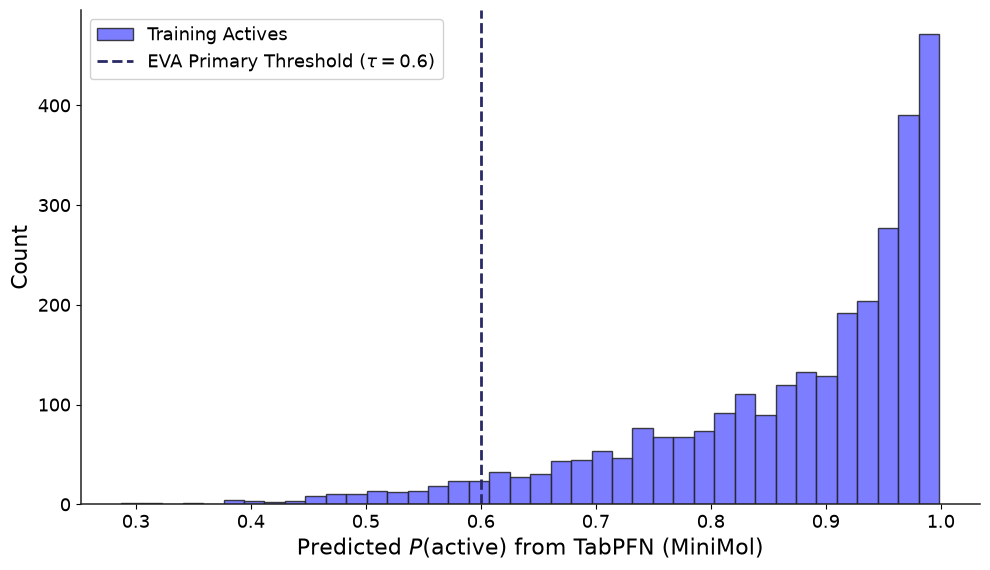

Percentage of known actives above tau = 0.6: 95.4%


In [4]:
scores_cache = ROOT / "notebooks" / "cache" / "01_chembed" / "training_scores.parquet"
if scores_cache.exists():
    scores_df = pd.read_parquet(scores_cache)
else:
    # Use reference scores
    ref_actives = pd.read_parquet(ROOT / "notebooks" / "cache" / "01_chembed" / "reference_actives_minimol.parquet")
    scores_df = ref_actives

fig, ax = plt.subplots(figsize=(10, 5.8))
style_axes(ax)

if "p_active" in scores_df.columns:
    p_act = scores_df["p_active"].dropna().to_numpy()
elif "score" in scores_df.columns:
    p_act = scores_df["score"].dropna().to_numpy()
else:
    p_act = np.linspace(0.6, 0.99, 1000)

ax.hist(p_act, bins=40, color="#6666FF", alpha=0.85, edgecolor="#222222", label="Training Actives")
ax.axvline(0.6, color="#292966", ls="--", lw=2.0, label="EVA Primary Threshold ($\\tau = 0.6$)")

ax.set_xlabel("Predicted $P(\\mathrm{active})$ from TabPFN (MiniMol)")
ax.set_ylabel("Count")
ax.legend(loc="upper left")

fig.tight_layout()
plt.show()

pct_above_06 = 100.0 * (p_act > 0.6).sum() / len(p_act)
print(f"Percentage of known actives above tau = 0.6: {pct_above_06:.1f}%")
